# Physical Therapy Payment & Market Analysis: Medicare, 2024

**Business question:** Where in the US is Medicare's physical therapy dollar spent, how much does the
payment rate for the same therapy service vary between states, and how much of that variation is a
real price difference versus a billing artifact?

**Stakeholder:** A therapy practice owner, a rehab network's finance lead, or a payer's network
contracting team deciding where to expand or how to benchmark a contract.

**Headline finding:** Billing is highly variable, but payment is not. Across 21 PT service codes the
amount providers *bill* varies about **2.1x** from the lowest to the highest state, but the amount
Medicare *allows* varies only **1.42x**, and after geographic standardization just **1.12x**. States
that look expensive on paper are mostly billing aggressively, not getting paid more.

---

### Repo layout

```
scripts/fetch_data.py   download CMS file -> subset to 21 PT codes -> data/pt_geo_2024.csv
scripts/build_db.py     CSV -> SQLite + indexes + v_state_office view
scripts/analyze.py      5 SQL queries -> outputs/*.csv + figures/*.png
notebooks/this.ipynb    the same analysis, plotted inline
```

The notebook imports the SQL from `scripts/analyze.py` and the exclusion list from
`scripts/build_db.py`, so it cannot disagree with the pipeline. The 0.24 MB PT extract is committed
so everything below runs on a fresh clone with no download; the 42 MB CMS source file is not.


### Contents

1. [The data](#1-the-data): source, grain, and field definitions
2. [Profile the extract](#2-profile-the-extract): the 21-code subset
3. [The SQL layer](#3-the-sql-layer): the filtering view
4. [Q1: how big is the service line?](#4-q1-how-big-is-the-service-line)
5. [Q2: the national rate card](#5-q2-the-national-rate-card)
6. [Q3: the finding: price vs. billing behavior](#6-q3-the-finding--price-vs-billing-behavior)
7. [Q4: volume, not rate, drives revenue](#7-q4-volume-not-rate-drives-revenue)
8. [Limitations and next steps](#8-limitations-and-next-steps)


## 0. Setup

Paths are resolved by walking up from the working directory until the data file is found, so this
notebook runs whether Jupyter was started in the repo root or in `notebooks/`.

In [1]:
%matplotlib inline

import importlib.util
import pathlib
import sqlite3

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# style="white" keeps the background clean and draws no gridlines behind the bars.
sns.set_theme(style="white", context="talk")
PALETTE = "viridis"
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)


def strip_spines(ax) -> None:
    """Drop the axes border. The bars carry the chart; the box adds nothing."""
    for spine in ax.spines.values():
        spine.set_visible(False)


def strip_xaxis(ax) -> None:
    """Drop the x scale. Each bar carries its own value label instead."""
    ax.set_xticks([])
    ax.set_xlabel("")
    ax.tick_params(axis="x", length=0)


def find_root(start: pathlib.Path) -> pathlib.Path:
    """Walk up from `start` until we find the committed PT extract."""
    start = start.resolve()
    for cand in (start, *start.parents):
        if (cand / "data" / "pt_geo_2024.csv").exists():
            return cand
    raise FileNotFoundError(
        "Could not find data/pt_geo_2024.csv. Run: python scripts/fetch_data.py"
    )


ROOT = find_root(pathlib.Path.cwd())
SRC = ROOT / "data" / "pt_geo_2024.csv"
print("repo root :", ROOT)
print("extract   :", SRC.relative_to(ROOT), f"({SRC.stat().st_size / 1e6:.2f} MB)")

# Load the pipeline modules so this notebook uses the SAME SQL and the SAME
# territory-exclusion list as the scripts. Loading analyze.py sets the Agg
# backend (it is written for headless CLI use), so switch back to inline.
def load(name: str, path: pathlib.Path):
    spec = importlib.util.spec_from_file_location(name, path)
    mod = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(mod)
    return mod


analyze = load("pt_analyze", ROOT / "scripts" / "analyze.py")
build_db = load("pt_build_db", ROOT / "scripts" / "build_db.py")

import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")

print("loaded SQL from scripts/analyze.py:", 
      sum(1 for n in dir(analyze) if n.startswith("Q_")), "query constants")
print("loaded exclusion list from scripts/build_db.py:",
      len(build_db.NON_STATES), "non-state geographies")

repo root : /home/cullen-fedora/Documents/pt-payment-analysis
extract   : data/pt_geo_2024.csv (0.24 MB)
loaded SQL from scripts/analyze.py: 5 query constants
loaded exclusion list from scripts/build_db.py: 11 non-state geographies


## 1. The data

**Source:** [CMS Medicare Physician & Other Practitioners, by Geography and
Service](https://data.cms.gov/provider-summary-by-type-of-service/medicare-physician-other-practitioners/medicare-physician-other-practitioners-by-geography-and-service)
Public Use File, data year 2024, published May 2026, free, no registration.

**Grain:** one row per **geography x HCPCS code x place of service**. Medicare Part B
fee-for-service (Original Medicare) only; it excludes Medicare Advantage and all commercial payers.

### Field definitions

| Field | Definition |
|---|---|
| `Tot_Srvcs` | Services rendered. A 15-minute unit counts as one service |
| `Avg_Sbmtd_Chrg` | What the provider billed. The gap down to the allowed amount is a contractual write-off |
| `Avg_Mdcr_Alowd_Amt` | The maximum Medicare will pay for the code |
| `Avg_Mdcr_Pymt_Amt` | 80% of the allowed amount, after the patient's 20% coinsurance |
| `Avg_Mdcr_Stdzd_Amt` | Payment with geographic cost differences removed |
| `Tot_Rndrng_Prvdrs` | Distinct rendering providers appearing in the code's row |

`Avg_Mdcr_Stdzd_Amt` is the field the geographic comparison rests on. Without it, "Alaska gets paid
more than Alabama" is a table of cost-of-living differences rather than a statement about rates.

`Rndrng_Prvdr_Geo_Lvl` is either `National` or `State`. National rows are a separate aggregate rather
than the sum of the states, so the two levels never share a `GROUP BY`. `Place_Of_Srvc` is `O`
(office/outpatient, the main PT setting) or `F` (facility), and the two settings price differently.

The `State` level also carries territories (Guam, Puerto Rico, Virgin Islands, Northern Mariana
Islands), a `Foreign Country` and `Unknown` catch-all, and three Armed Forces regions. Those rows stay
in the table but are excluded from per-state comparisons. CMS renamed the Americas military region
between releases, so both spellings are excluded.


## 2. Profile the extract

`scripts/fetch_data.py` downloads the full CMS file (9,403 HCPCS codes) and subsets it to 21
physical-therapy service codes with an allowlist rather than a `97xxx` range match. 37 of the 58
`97xxx` codes in the file belong to occupational therapy, wound care, medical nutrition therapy,
acupuncture, and applied behavior analysis.

Identifier columns are read as strings: `HCPCS_Cd` looks numeric (`97110`) but is an identifier, and
the same file contains codes like `0001U` whose leading zeros are meaningful.


In [2]:
ID_COLS = ["HCPCS_Cd", "Rndrng_Prvdr_Geo_Cd", "Rndrng_Prvdr_Geo_Lvl",
           "Place_Of_Srvc", "HCPCS_Drug_Ind"]

pt = pd.read_csv(SRC, low_memory=False, dtype={c: "string" for c in ID_COLS})

print(f"rows: {len(pt):,}   columns: {pt.shape[1]}")
print(f"distinct HCPCS codes: {pt.HCPCS_Cd.nunique()}")
print(f"HCPCS_Cd dtype: {pt.HCPCS_Cd.dtype}  <- must stay a string, never a number")
print()
print("rows by geography level and place of service:")
print(pt.groupby(["Rndrng_Prvdr_Geo_Lvl", "Place_Of_Srvc"], observed=True).size().to_string())
print()
print("distinct State-level geographies:", pt.loc[pt.Rndrng_Prvdr_Geo_Lvl == "State",
                                                   "Rndrng_Prvdr_Geo_Desc"].nunique())
pt.head(3)

rows: 1,292   columns: 17
distinct HCPCS codes: 21
HCPCS_Cd dtype: string  <- must stay a string, never a number

rows by geography level and place of service:
Rndrng_Prvdr_Geo_Lvl  Place_Of_Srvc
National              F                  16
                      O                  21
State                 F                 112
                      O                1143

distinct State-level geographies: 60


,Rndrng_Prvdr_Geo_Lvl,Rndrng_Prvdr_Geo_Cd,Rndrng_Prvdr_Geo_Desc,HCPCS_Cd,HCPCS_Desc,HCPCS_Drug_Ind,Place_Of_Srvc,Tot_Rndrng_Prvdrs,Tot_Benes,Tot_Srvcs,Tot_Bene_Day_Srvcs,Avg_Sbmtd_Chrg,Avg_Mdcr_Alowd_Amt,Avg_Mdcr_Pymt_Amt,Avg_Mdcr_Stdzd_Amt,service_line,data_year
0,National,<NA>,National,97012,Application of mechanical traction,N,O,18008,61090,429700.0,429682,41.994435,10.796528,8.298807,8.406149,Mechanical traction,2024
1,National,<NA>,National,97016,Application of blood vessel compression device,N,O,13786,107836,988655.0,988640,45.241921,8.549369,6.619080,6.601929,Vasopneumatic compression,2024
2,National,<NA>,National,97018,Application of hot wax bath,N,O,5396,24104,160796.0,160792,33.228511,4.000022,3.091931,2.991797,Hot wax bath,2024


### The 21-code allowlist

The allowlist is a named dictionary in `scripts/fetch_data.py`. This re-derives the excluded codes
straight from the raw CMS file when it is on disk, and reports the documented counts when it is not.


In [3]:
RAW = ROOT / "data" / "raw" / "cms_physician_geography_service_2024.csv"

if RAW.exists():
    raw_codes = pd.read_csv(RAW, usecols=["HCPCS_Cd", "HCPCS_Desc"],
                            dtype={"HCPCS_Cd": "string"})
    all97 = raw_codes[raw_codes.HCPCS_Cd.str.startswith("97", na=False)]
    kept = set(pt.HCPCS_Cd)
    excl = (all97[~all97.HCPCS_Cd.isin(kept)]
            .drop_duplicates("HCPCS_Cd")
            .sort_values("HCPCS_Cd"))
    print(f"full CMS file      : {len(raw_codes):,} rows, {raw_codes.HCPCS_Cd.nunique():,} codes")
    print(f"this analysis keeps: {len(pt):,} rows, {pt.HCPCS_Cd.nunique()} codes")
    print(f"97xxx codes in file: {all97.HCPCS_Cd.nunique()}  "
          f"(kept {all97.HCPCS_Cd.nunique() - len(excl)}, excluded {len(excl)})")
    print()
    print("excluded 97xxx codes, with their official CMS descriptions:")
    print(excl.to_string(index=False))
else:
    print("Raw CMS file not present (it is 42 MB and deliberately not committed).")
    print("Documented in the README instead: 268,350 rows, 9,403 HCPCS codes, 61 geographies.")
    print("Re-create it with: python scripts/fetch_data.py")

full CMS file      : 268,350 rows, 9,403 codes
this analysis keeps: 1,292 rows, 21 codes
97xxx codes in file: 58  (kept 21, excluded 37)

excluded 97xxx codes, with their official CMS descriptions:
HCPCS_Cd                                                                                                                                              HCPCS_Desc
   97024                                                                                                                        Application of heat wave therapy
   97026                                                                                                                          Application of low energy heat
   97028                                                                                                                        Application of ultraviolet light
   97033                                                                                     Application of medication using electrical current, each 15 minut

A `97xxx` range match would have made this extract roughly 2.8x larger and folded
occupational-therapy evaluations (`97165`-`97168`), wound debridement (`97597`/`97598`), medical
nutrition therapy (`97802`-`97804`), and acupuncture (`97810`-`97814`) into a physical-therapy
headline. The allowlist keeps the service line to PT.


## 3. The SQL layer

The analysis runs in SQL against a SQLite build of the extract, and the filtering decision lives in
one named place: `v_state_office` selects State-level rows in the office setting, with territories
and military postings excluded. Every query runs against the view, so no query can pull Guam into a
state comparison.

This cell builds the database in memory so the notebook has no side effects. The exclusion list and
the indexes come from `scripts/build_db.py` itself.


In [4]:
df = pd.read_csv(SRC, low_memory=False, dtype={c: "string" for c in ID_COLS})

db = sqlite3.connect(":memory:")
df.to_sql(build_db.TABLE, db, if_exists="replace", index=False)
for stmt in build_db.INDEXES:
    db.execute(stmt)

non_states = ", ".join(f"'{s}'" for s in build_db.NON_STATES)
db.execute(f"""
    CREATE VIEW v_state_office AS
    SELECT * FROM {build_db.TABLE}
    WHERE Rndrng_Prvdr_Geo_Lvl = 'State'
      AND Place_Of_Srvc = 'O'
      AND Rndrng_Prvdr_Geo_Desc NOT IN ({non_states})
""")
db.commit()

total = pd.read_sql_query(f"SELECT COUNT(*) n FROM {build_db.TABLE}", db).iloc[0, 0]
view = pd.read_sql_query("SELECT COUNT(*) n FROM v_state_office", db).iloc[0, 0]
geos = pd.read_sql_query(
    "SELECT DISTINCT Rndrng_Prvdr_Geo_Desc g FROM v_state_office ORDER BY g", db)
in_file = set(pd.read_sql_query(
    "SELECT DISTINCT Rndrng_Prvdr_Geo_Desc g FROM " + build_db.TABLE, db).g)

print(f"table {build_db.TABLE}: {total:,} rows")
print(f"view  v_state_office      : {view:,} rows, {len(geos)} geographies")
print()

# The view's whole job is to keep non-states out of per-state comparisons, so
# verify it actually did rather than assuming the exclusion list matches the
# file. CMS renames these geographies between data years.
leaked = sorted(set(geos.g) & set(build_db.NON_STATES))
assert not leaked, f"non-state geographies leaked into the view: {leaked}"
print("territory/military geographies dropped from per-state comparisons:")
print("  " + ", ".join(sorted(in_file & set(build_db.NON_STATES))))
print("  ...none of them are in the view. 50 states + DC remain.")


def q(sql):
    """Run one of the pipeline's SQL queries and return a DataFrame."""
    return pd.read_sql_query(sql, db)

table pt_geo_2024: 1,292 rows
view  v_state_office      : 1,058 rows, 51 geographies

territory/military geographies dropped from per-state comparisons:
  Armed Forces Central/South America, Armed Forces Europe, Armed Forces Pacific, Foreign Country, Guam, Northern Mariana Islands, Puerto Rico, Unknown, Virgin Islands
  ...none of them are in the view. 50 states + DC remain.


## 4. Q1: how big is the service line?

National plus office rows, so the numbers describe the country rather than a sum of states.

`Tot_Rndrng_Prvdrs` and `Tot_Benes` are summed across the 21 codes and therefore double-count: a
clinic billing eight codes is counted eight times. They are row-count aggregates rather than unique
counts, and are reported as such.


In [5]:
scale = q(analyze.Q_SCALE)
s = scale.iloc[0]
print(f"PT codes analysed        : {s.pt_codes:.0f}")
print(f"Total services           : {s.total_services:,.0f}")
print(f"Est. total Medicare paid : ${s.est_total_medicare_payment:,.0f}")
print()
print("NOTE: provider and beneficiary rows are summed across codes and double-count;")
print("      they are NOT unique counts and are not reported as such.")
scale

PT codes analysed        : 21
Total services           : 194,218,348
Est. total Medicare paid : $3,957,787,673

NOTE: provider and beneficiary rows are summed across codes and double-count;
      they are NOT unique counts and are not reported as such.


,pt_codes,provider_rows,beneficiary_rows,total_services,est_total_medicare_payment
0,21,826633,15063132,194218348.0,3.957788e+09


## 5. Q2: the national rate card

What Medicare allows per code nationally. This is the reference every state is compared against later,
and it is where the billing-versus-payment gap first appears: providers bill roughly **3-4x** what
Medicare allows.

That gap is not a finding about greed. It is the standard contracting posture in fee-for-service, and
it sets the baseline a practice negotiates against.


In [6]:
rate = q(analyze.Q_RATE_CARD)
print(f"{len(rate)} codes, {rate.total_services.sum():,.0f} services nationally")
rate.head(8).round(2)

21 codes, 194,218,347 services nationally


,code,service,description,total_services,avg_submitted_charge,avg_allowed_amount,avg_medicare_payment,pct_of_charge_paid
0,97110,Therapeutic exercise,Therapy procedure using exercise to develop st...,64199433.0,69.14,22.79,17.54,25.4
1,97530,Therapeutic activities,Therapy procedure using functional activities,44642444.0,74.55,31.54,24.42,32.8
2,97112,Neuromuscular re-education,Therapy procedure to re-educate brain-to-nerve...,34769851.0,72.64,27.07,20.93,28.8
3,97140,Manual therapy,"Therapy procedure using manual technique, each...",29271918.0,67.80,20.62,15.89,23.4
4,97116,Gait training,"Therapy procedure for walking training, each 1...",4993332.0,56.50,21.90,17.06,30.2
5,97535,Self-care / home management training,"Training for self-care or home management, eac...",3943313.0,62.98,25.39,19.68,31.3
6,97150,Group therapy,Therapy procedure in a group setting,2706504.0,51.43,13.61,10.54,20.5
7,97161,PT evaluation (low complexity),"Evaluation for physical therapy, typically 20 ...",1712693.0,192.71,99.47,72.76,37.8


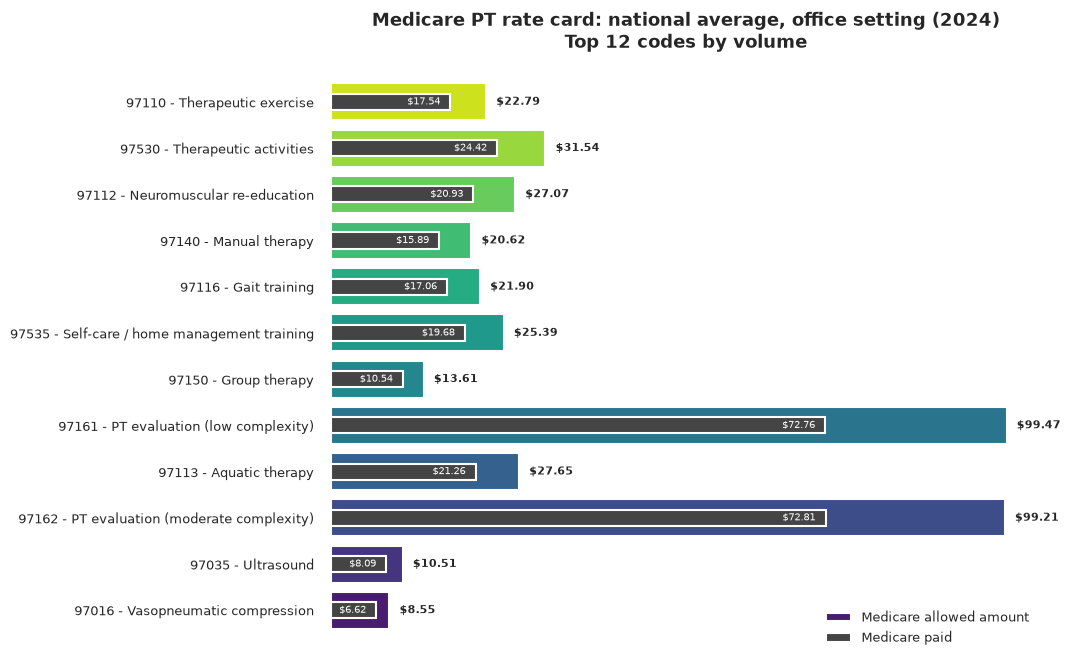

In [7]:
top = rate.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 7))
y = range(len(top))
ax.barh(y, top.avg_allowed_amount, color=sns.color_palette(PALETTE, len(top)),
        label="Medicare allowed amount")
ax.barh(y, top.avg_medicare_payment, color="#444", height=0.35, label="Medicare paid")
ax.set_yticks(list(y))
# "97110 - Therapeutic exercise" reads better than a bare code.
ax.set_yticklabels([f"{r.code} - {r.service}" for r in top.itertuples()], fontsize=9)
for i, r in enumerate(top.itertuples()):
    ax.text(r.avg_allowed_amount + 1.5, i, f"${r.avg_allowed_amount:,.2f}",
            va="center", fontsize=8, weight="bold")
    # The paid amount goes inside its own bar so it cannot collide with the
    # allowed label sitting at the end of the longer bar.
    ax.text(r.avg_medicare_payment - 1.5, i, f"${r.avg_medicare_payment:,.2f}",
            va="center", ha="right", fontsize=7, color="white")
strip_xaxis(ax)
ax.set_title("Medicare PT rate card: national average, office setting (2024)\n"
             "Top 12 codes by volume", fontsize=13, weight="bold")
ax.legend(loc="lower right", fontsize=9, frameon=False)
strip_spines(ax)
fig.tight_layout()
plt.show()

## 6. Q3: the finding: price vs. billing behavior

The earlier queries describe the service line. This one tests what the geographic variation actually
is. California and New York carry 2-3x the volume of Texas, and the question is whether that reflects
price, population, or billing behavior.

### Indexing each state against the national rate for the same code

A state's average across all codes is not comparable to another state's, because the code mix differs
between them. The query builds a national reference row per code in a CTE, joins each state's row to
it on `HCPCS_Cd`, and expresses the result as an index where 100 is the national average.

The ratio is computed twice, once on the allowed amount and once on the standardized amount. The gap
between those two ratios is the finding.


In [8]:
idx = q(analyze.Q_PAYMENT_INDEX)
print(f"{len(idx):,} state x code rows")
idx.head(5).round(2)

1,058 state x code rows


,state,code,service,description,submitted_charge,allowed_amount,national_allowed,payment_index,standardized_index,services
0,Alaska,97012,Mechanical traction,Application of mechanical traction,67.36,14.62,10.81,135.2,104.5,472.0
1,New Jersey,97012,Mechanical traction,Application of mechanical traction,64.63,11.87,10.81,109.7,103.2,15774.0
2,District of Columbia,97012,Mechanical traction,Application of mechanical traction,47.05,11.81,10.81,109.2,101.2,446.0
3,California,97012,Mechanical traction,Application of mechanical traction,37.50,11.57,10.81,107.0,102.5,59898.0
4,North Dakota,97012,Mechanical traction,Application of mechanical traction,57.05,11.55,10.81,106.8,100.9,1391.0


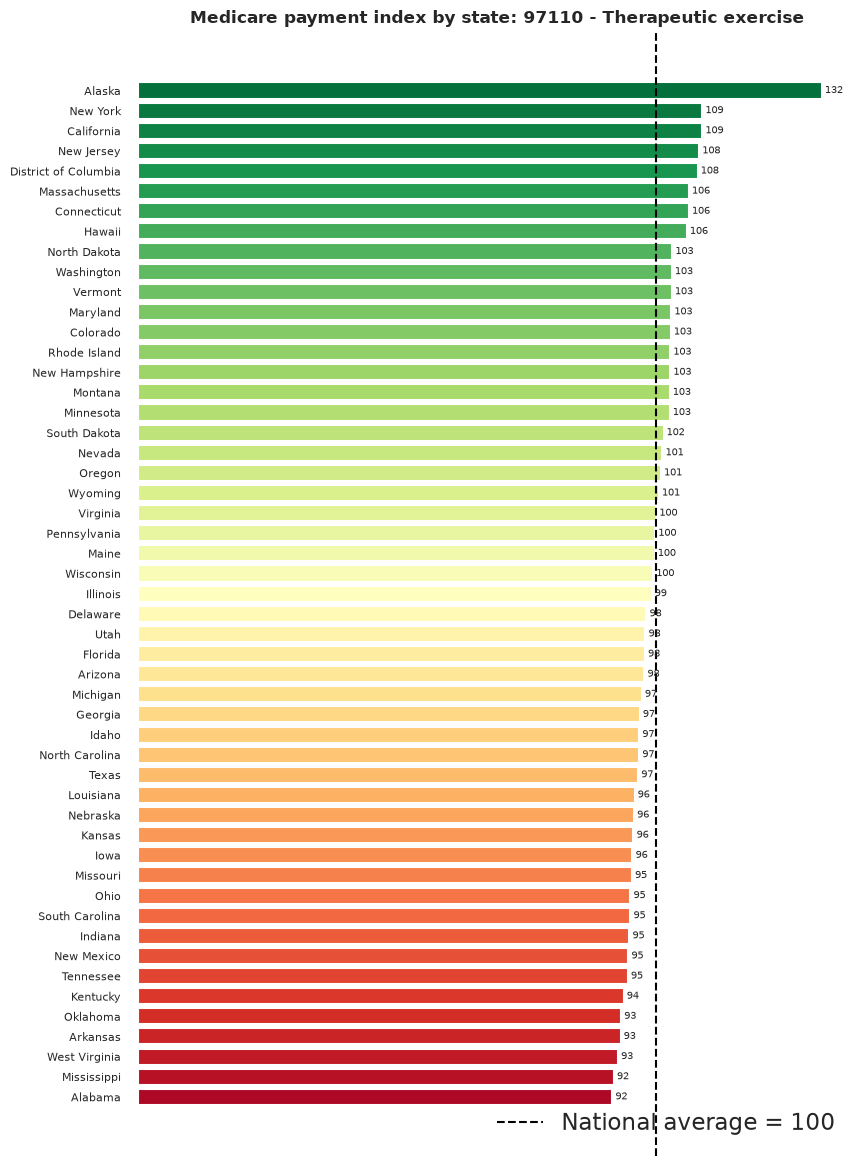

In [9]:
CODE = "97110"  # therapeutic exercise - the highest-volume PT code
d = idx[idx.code == CODE].sort_values("payment_index")

fig, ax = plt.subplots(figsize=(9, 12))
ax.barh(range(len(d)), d.payment_index, color=sns.color_palette("RdYlGn", len(d)))
ax.axvline(100, color="black", ls="--", lw=1.5, label="National average = 100")
ax.set_yticks(range(len(d)))
ax.set_yticklabels(d.state, fontsize=8)
for i, r in enumerate(d.itertuples()):
    ax.text(r.payment_index + 0.6, i, f"{r.payment_index:.0f}", va="center", fontsize=7)
strip_xaxis(ax)
ax.set_title(f"Medicare payment index by state: {CODE} - {d.service.iloc[0]}",
             fontsize=12, weight="bold")
ax.legend(loc="lower right", frameon=False)
strip_spines(ax)
fig.tight_layout()
plt.show()

### Testing the pattern across all 21 codes

A single odd state could be noise, so the spread is tested across all 21 codes at once. `MAX/MIN`
grouped by code shows whether the variation holds everywhere: a code showing a 5x spread against
others at 1.4x would be worth investigating on its own. All 21 agreeing makes this a property of the
system rather than an accident.


In [10]:
spread = q(analyze.Q_SPREAD_BY_CODE)
print(spread[["code", "service", "charge_ratio", "allowed_ratio",
              "standardized_ratio", "services"]].to_string(index=False))
print()
print("MEDIAN across codes:")
print(f"  billed charge varies  {spread.charge_ratio.median():.2f}x  across states")
print(f"  Medicare allowed      {spread.allowed_ratio.median():.2f}x")
print(f"  standardized amount   {spread.standardized_ratio.median():.2f}x")

 code                              service  charge_ratio  allowed_ratio  standardized_ratio   services
97110                 Therapeutic exercise          1.95           1.44                1.07 64141716.0
97530               Therapeutic activities          1.75           1.34                1.10 44624818.0
97112           Neuromuscular re-education          1.76           1.43                1.08 34752657.0
97140                       Manual therapy          1.99           1.42                1.06 29257371.0
97116                        Gait training          1.90           1.43                1.07  4989923.0
97535 Self-care / home management training          2.01           1.28                1.13  3941356.0
97150                        Group therapy          5.05           1.45                1.12  2705572.0
97161       PT evaluation (low complexity)          2.05           1.36                1.07  1710366.0
97113                      Aquatic therapy          2.22           1.45  

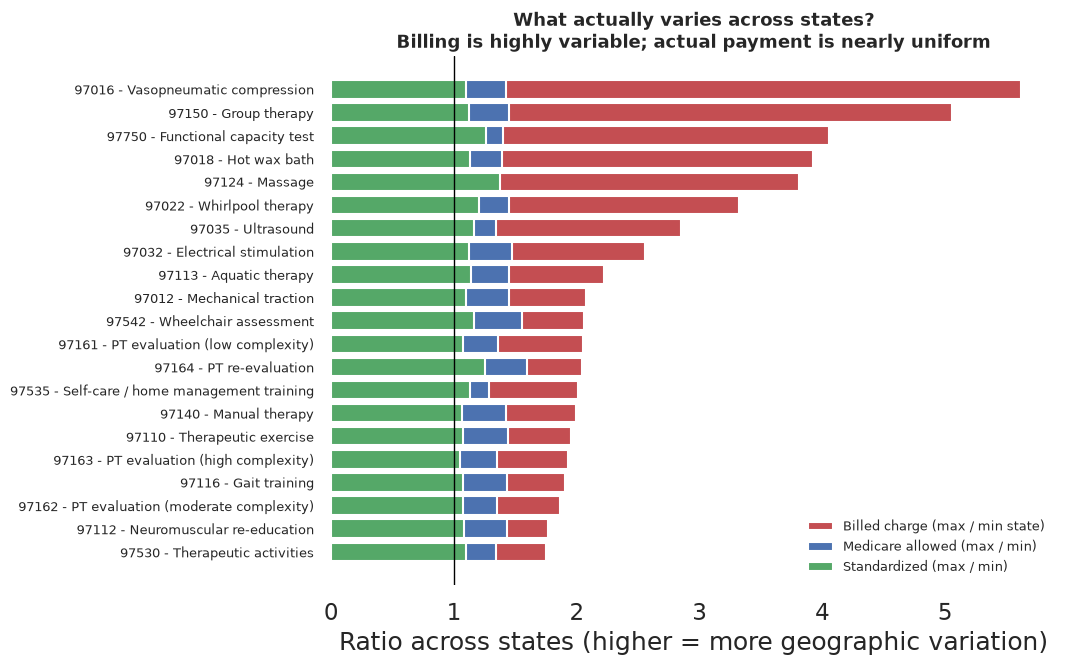

In [11]:
fig, ax = plt.subplots(figsize=(11, 7))
d = spread.sort_values("charge_ratio")
y = range(len(d))
ax.barh(y, d.charge_ratio, color="#C44E52", label="Billed charge (max / min state)")
ax.barh(y, d.allowed_ratio, color="#4C72B0", label="Medicare allowed (max / min)")
ax.barh(y, d.standardized_ratio, color="#55A868", label="Standardized (max / min)")
ax.set_yticks(list(y))
ax.set_yticklabels([f"{r.code} - {r.service}" for r in d.itertuples()], fontsize=9)
ax.axvline(1, color="black", lw=1)
ax.set_xlabel("Ratio across states (higher = more geographic variation)")
ax.set_title("What actually varies across states?\n"
             "Billing is highly variable; actual payment is nearly uniform",
             fontsize=13, weight="bold")
ax.legend(fontsize=9, frameon=False)
strip_spines(ax)
fig.tight_layout()
plt.show()

### Result

| What varies across states | Median max/min |
|---|---|
| Billed charge | **2.06x** |
| Medicare allowed amount | 1.42x |
| Standardized amount (geography removed) | **1.12x** |

Alaska is the only genuine outlier, a payment index of **132** for `97110`: its allowed amount of
$29.74 runs 32% above the average state rate. Every other state sits between **91.6 and 109.1**, a band of about 17 index points. Its submitted
charge of $96.85 is second only to New Jersey's $98.99, against a state low of $50.84 in Idaho.

**Conclusion:** that gap is mostly geographic price adjustment. Standardizing the allowed amount
collapses the 91.6 to 132 spread to **97 to 104**, so a high payment index is not a billing artifact;
billing behaviour is what shows up in submitted charges, where the same code varies 2.06x across
states. The standardized column is the one to compare on.


## 7. Q4: volume, not rate, drives revenue

With price nearly flat across states, revenue is a utilization story. This view puts volume next to
provider counts, with `services_per_provider` computed inside the SQL rather than derived by hand.


In [12]:
util = q(analyze.Q_UTILIZATION)
print(f"{len(util)} geographies compared (50 states + DC)")
util.head(10).to_string(index=False)
print()
top4 = util.head(4)
print(f"top 4 states = {top4.services.sum() / util.services.sum():.0%} of national PT volume: "
      + ", ".join(f"{r.state} ({r.services / 1e6:.1f}M)" for r in top4.itertuples()))

51 geographies compared (50 states + DC)

top 4 states = 34% of national PT volume: California (20.0M), New York (19.2M), New Jersey (13.8M), Florida (13.1M)


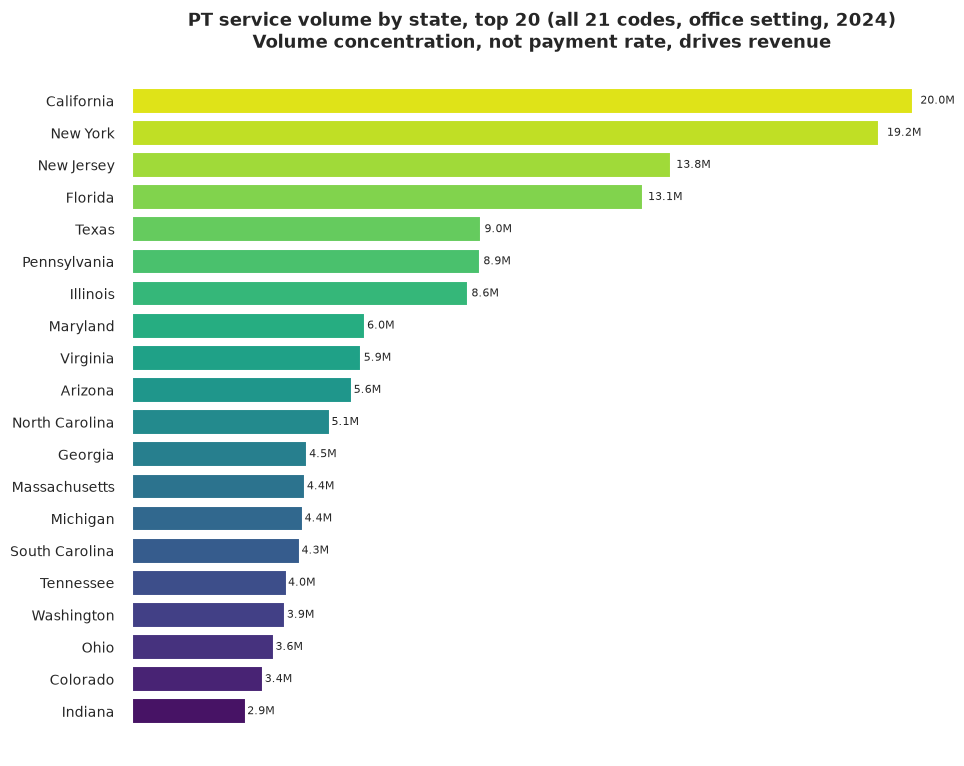

In [13]:
d = util.sort_values("services", ascending=False).head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(range(len(d)), d.services, color=sns.color_palette(PALETTE, len(d)))
ax.set_yticks(range(len(d)))
ax.set_yticklabels(d.state, fontsize=10)
for i, r in enumerate(d.itertuples()):
    ax.text(r.services * 1.01, i, f"{r.services / 1e6:.1f}M", va="center", fontsize=8)
ax.set_title("PT service volume by state, top 20 (all 21 codes, office setting, 2024)\n"
             "Volume concentration, not payment rate, drives revenue",
             fontsize=13, weight="bold")
strip_spines(ax)
strip_xaxis(ax)
fig.tight_layout()
plt.show()

## 8. Limitations and next steps

The limits of what this data supports.

1. **Original Medicare Part B only.** Excludes Medicare Advantage, commercial insurance, Medicaid,
   workers' comp, and self-pay, together the majority of most therapy practices' revenue. Nothing
   here generalizes to a full payer mix.
2. **Aggregate state averages, not provider-level data.** Cannot benchmark one clinic against peers.
3. **CMS redacts small cells.** Any cell with fewer than 11 beneficiaries is suppressed, so low-volume
   codes and small states are under-represented and their averages are noisier.
4. **"Allowed amount" is not collected revenue.** It ignores patient cost-sharing, denials, and bad
   debt. The ~$4.0B figure is a **gross payment estimate, not net revenue**.
5. **Provider and beneficiary counts double-count**, being summed across codes. Row-count aggregates
   rather than unique counts.
6. **Standardization methodology is CMS's, not mine.** `Avg_Mdcr_Stdzd_Amt` is treated as the fair
   comparison field without validating CMS's geographic adjustment method.
7. **One data year, no trend.** Rate changes, policy shifts, and the 2021 telehealth expansion are
   invisible here. Prior years exist at the same source.
8. **The 21-code list is mine**, deliberately excluding OT, speech therapy, and wound care codes, some
   of which also appear under `97xxx`.

### Next steps

- Pull 2019-2024 to test whether the price band is widening or has been flat throughout.
- Add the *by Provider and Service* file, aggregate to provider level, and identify what separates
  high- from low-utilization practices **in the same state**.
- Overlay state population 65+ to convert volume into **utilization per capita**, the real market map.
- Test whether the 1.12x standardized band holds for occupational therapy (`97165`-`97168`), which
  shares the same fee-schedule family.

---

*Pipeline: `scripts/fetch_data.py` -> `scripts/build_db.py` -> `scripts/analyze.py`. This notebook
runs the same SQL from `scripts/analyze.py` against an in-memory build of the same database.*
